In [34]:
from sklearn.svm import SVC
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [3]:
# loading data

data = np.load("data/processed_data.npz")

X_train_scaled = data["X_train_scaled"]
X_test_scaled = data["X_test_scaled"]
y_train = data["y_train"]
y_test = data["y_test"]

In [14]:
# Training classifiers and making predictions
# Linear

linear_svc = SVC(kernel='linear') #instancing  a classifier
linear_svc.fit(X_train_scaled, y_train)

#print(linear_svc.support_vectors_)

y_predictions_linear = linear_svc.predict(X_test_scaled)
print(y_predictions_linear)
print(y_predictions_linear.shape)


[1 0 1 1 0 1 1 1 1 1 1 1 0 1 1 1 1 0 0 1 0 1 0 1 0 0 1 1 1 1 1 1 0 0 1 1 0
 0 1 1 0 1 1 1 1 1 0 1 1 1 1 1 1 0 1 1 1 1 0 0 1 0 1 1 0 1 1 1 1 1 0 1 0 1
 1 1 1 0 1 0 1 1 0 1 1 0 1 1 1 1 1 1 0 1 1 1 1 0 1 1 1 1 1 0 1 1 1 0 1 1 1
 1 1 1 1 0 0 0 1 0 1 0 1 1 1 1 1 0 1 0 1 1 1 0 1 1 1 1 1 1 1 1 0 1 1 1 1 1
 1 0 1 1 1 0 1 1 1 1 1 1 0 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 0 1 1 1 1 0 1 1 1
 1 1 0 1 1 1 1 0 0 1 1 1 1 0 1 0 1 1 1 1 1 1 1 1 0 0 0 1 0 0 1 0 1 0 1 1 1
 1 0 1 1 1 1 0 1 1 1 1 1 1 1 1 1 1 1 1 1 0 0 0 1 1 0 1 1 1 1 0 1 1 0 1 0 1
 0 1 0 1 0 0 1 1 1 1 1 1 1 0 1 0 0 1 1 1 1 1 1 1 1 1 1 1 1 1 0 0 1 1 1 1 1
 1 1 1 1]
(300,)


In [23]:
# Polynomial

poly_svc = SVC(kernel='poly')
poly_svc.fit(X_train_scaled, y_train)

#print(poly_svc.support_vectors_)

y_predictions_poly = poly_svc.predict(X_test_scaled)

,"kernel kernel: {'linear', 'poly', 'rbf', 'sigmoid', 'precomputed'} or callable, default='rbf'Specifies the kernel type to be used in the algorithm. Ifnone is given, 'rbf' will be used. If a callable is given it is used topre-compute the kernel matrix from data matrices; that matrix should bean array of shape ``(n_samples, n_samples)``. For an intuitivevisualization of different kernel types see:ref:`sphx_glr_auto_examples_svm_plot_svm_kernels.py`.",'poly'
,"C C: float, default=1.0Regularization parameter. The strength of the regularization isinversely proportional to C. Must be strictly positive. The penaltyis a squared l2 penalty. For an intuitive visualization of the effectsof scaling the regularization parameter C, see:ref:`sphx_glr_auto_examples_svm_plot_svm_scale_c.py`.",1.0
,"degree degree: int, default=3Degree of the polynomial kernel function ('poly').Must be non-negative. Ignored by all other kernels.",3
,"gamma gamma: {'scale', 'auto'} or float, default='scale'Kernel coefficient for 'rbf', 'poly' and 'sigmoid'.- if ``gamma='scale'`` (default) is passed then it uses 1 / (n_features * X.var()) as value of gamma,- if 'auto', uses 1 / n_features- if float, must be non-negative... versionchanged:: 0.22 The default value of ``gamma`` changed from 'auto' to 'scale'.",'scale'
,"coef0 coef0: float, default=0.0Independent term in kernel function.It is only significant in 'poly' and 'sigmoid'.",0.0
,"shrinking shrinking: bool, default=TrueWhether to use the shrinking heuristic.See the :ref:`User Guide <shrinking_svm>`.",True
,"probability probability: bool, default=FalseWhether to enable probability estimates. This must be enabled priorto calling `fit`, will slow down that method as it internally uses5-fold cross-validation, and `predict_proba` may be inconsistent with`predict`. Read more in the :ref:`User Guide <scores_probabilities>`...deprecated:: 1.9 The `probability` parameter is deprecated and will be removed in 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`.",'deprecated'
,"tol tol: float, default=1e-3Tolerance for stopping criterion.",0.001
,"cache_size cache_size: float, default=200Specify the size of the kernel cache (in MB).",200
,"class_weight class_weight: dict or 'balanced', default=NoneSet the parameter C of class i to class_weight[i]*C forSVC. If not given, all classes are supposed to haveweight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.",None
,"verbose verbose: bool, default=FalseEnable verbose output. Note that this setting takes advantage of aper-process runtime setting in libsvm that, if enabled, may not workproperly in a multithreaded context.",False


In [20]:
# RBF

rbf_svc = SVC(kernel='rbf')
rbf_svc.fit(X_train_scaled, y_train)
#print(rbf_svc.support_vectors_)

y_predictions_rbf = rbf_svc.predict(X_test_scaled)




In [18]:
# saving results in a dataframe

results = pd.DataFrame({
    "actual classes" : y_test,
    "linear svc predictions" : y_predictions_linear,
    "poly svc predictions" : y_predictions_poly,
    "rbf svc predictions" : y_predictions_rbf
}
)

results ["correct linear predictions"] = results["actual classes"] == results["linear svc predictions"]
results ["correct poly predictions"] = results["actual classes"] == results["poly svc predictions"]
results ["correct rbf predictions"] = results["actual classes"] == results["rbf svc predictions"]

print(results)

     actual classes  linear svc predictions  poly svc predictions  \
0                 1                       1                     1   
1                 1                       0                     1   
2                 1                       1                     1   
3                 1                       1                     1   
4                 0                       0                     1   
..              ...                     ...                   ...   
295               0                       1                     1   
296               0                       1                     1   
297               0                       1                     1   
298               0                       1                     1   
299               0                       1                     1   

     rbf svc predictions  correct linear predictions  \
0                      1                        True   
1                      1                       False   
2  

In [22]:
# saving results

results.to_csv("data/prediction_results.csv", index=False)

In [37]:
# VISUALIZING DECISION BOUNDARIES

# creating grid
x1_min, x1_max = X_train_scaled[:, 0].min() - 0.5, X_train_scaled[:, 0].max() + 0.5
x2_min, x2_max = X_train_scaled[:, 1].min() - 0.5, X_train_scaled[:, 1].max() + 0.5

xx, yy = np.meshgrid(
    np.linspace(x1_min, x1_max, 500),
    np.linspace(x2_min, x2_max, 500)
)

grid = np.c_[xx.ravel(), yy.ravel()]

In [40]:
# predicting points all across the grid as if they were data points
predictions = {
    "linear SVC": linear_svc.predict(grid).reshape(xx.shape),
    "polynomial kernel with default parameters": poly_svc.predict(grid).reshape(xx.shape),
    "rbf kernel with default parameters": rbf_svc.predict(grid).reshape(xx.shape)
}

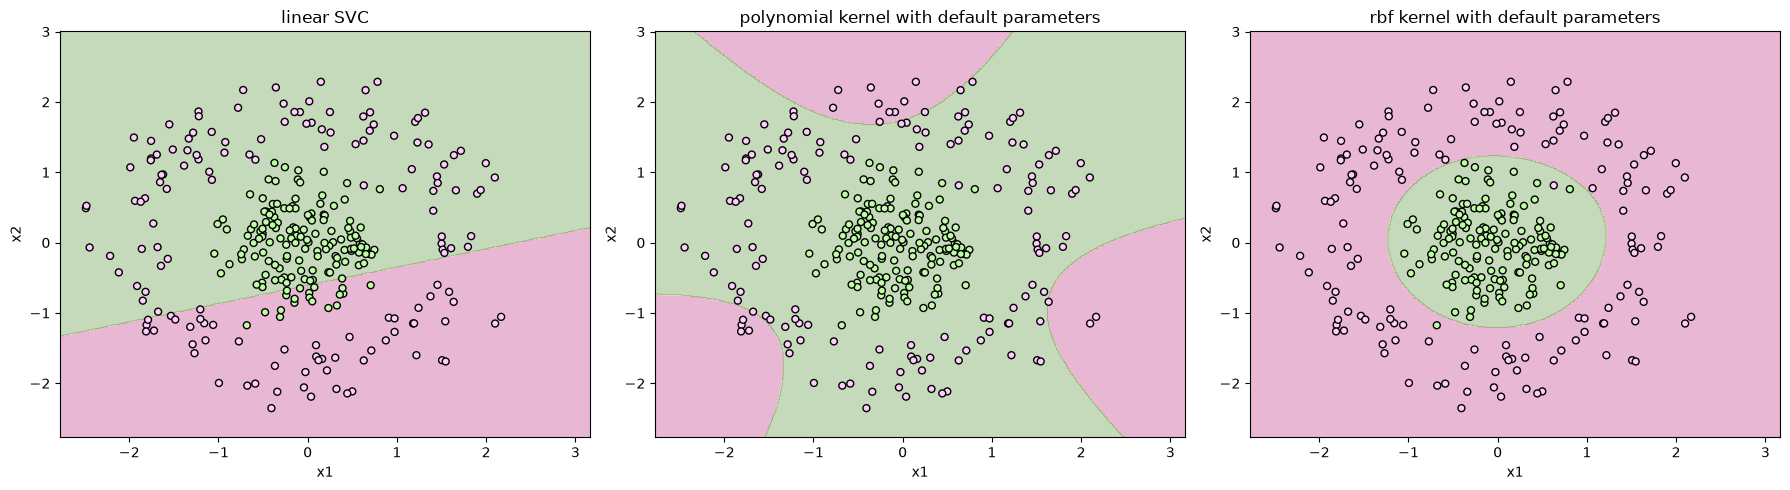

In [45]:
# plotting grid and decision boundary

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, (name, Z) in zip(axes, predictions.items()):

    # Plot the predicted regions
    ax.contourf(xx, yy, Z, alpha=0.3, cmap="PiYG")

    # Plot the actual data points
    ax.scatter(
        X_test_scaled[:, 0],
        X_test_scaled[:, 1],
        c=y_test,
        cmap="vanimo",
        edgecolors="black",
        s=25
    )

    ax.set_title(f"{name}")
    ax.set_xlabel("x1")
    ax.set_ylabel("x2")

plt.tight_layout()
plt.show()